In [1]:
# import library
import pandas as pd 
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

In [2]:
data = pd.read_csv("train.csv")

In [3]:
data.head()

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [4]:
data.shape

(3000888, 6)

In [5]:
data.isna().sum()

id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

In [6]:
# Check duplicate 
data.duplicated().sum()

0

In [7]:
# Change date to datetime 
data['date'] = pd.to_datetime(data['date'])

# Exploratory Data Analysis

In [8]:
# Total Sales 
data['sales'].sum()

1073644952.2030689

In [9]:
# Exploratory Date
data.head()

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [10]:
#First date 
data['date'].min()

Timestamp('2013-01-01 00:00:00')

In [11]:
# Last dat 
data['date'].max()

Timestamp('2017-08-15 00:00:00')

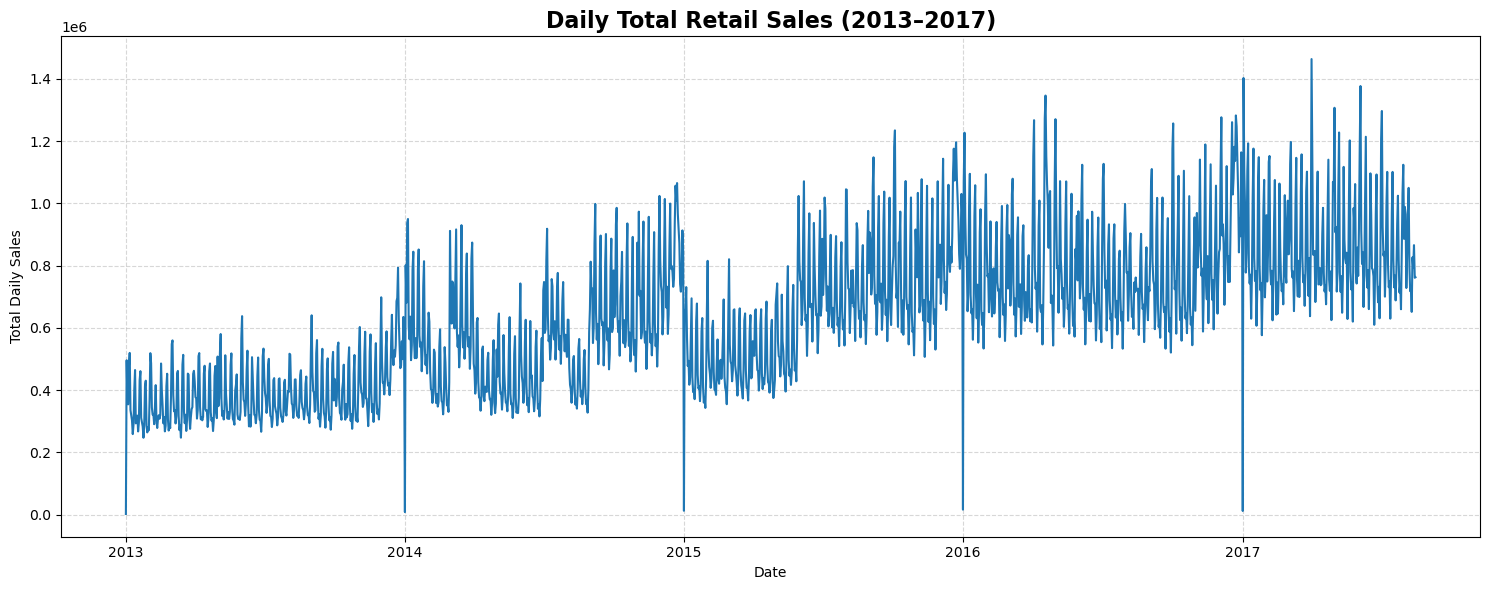

In [12]:
# Daily Retails Sales 
daily_sales = data.groupby('date')['sales'].sum().reset_index()

plt.figure(figsize=(15, 6))

sns.lineplot(
    x='date',
    y='sales',
    data=daily_sales
)

plt.title('Daily Total Retail Sales (2013–2017)',
          fontsize=16, fontweight='bold')

plt.xlabel('Date')
plt.ylabel('Total Daily Sales')

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [13]:
# Create year, month and day columns 
data['year'] = data['date'].dt.year
data['month'] = data ['date'].dt.month
data['day_of_week'] = data["date"].dt.dayofweek

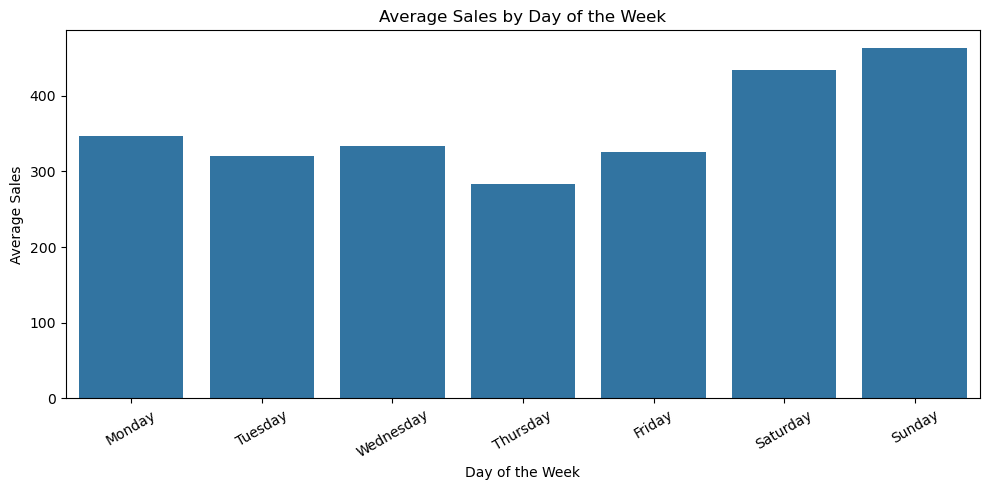

In [15]:
# Sales by day of the week
weekly_sales = (data.groupby("day_of_week")["sales"].mean().reset_index())

# Visualiazing 
plt.figure(figsize=(10, 5))

sns.barplot(data=weekly_sales,x="day_of_week",y="sales")


plt.title("Average Sales by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Sales")
plt.xticks(ticks=range(7),labels=["Monday", "Tuesday", "Wednesday", "Thursday",
            "Friday", "Saturday", "Sunday"],rotation=30)

plt.tight_layout()
plt.show()

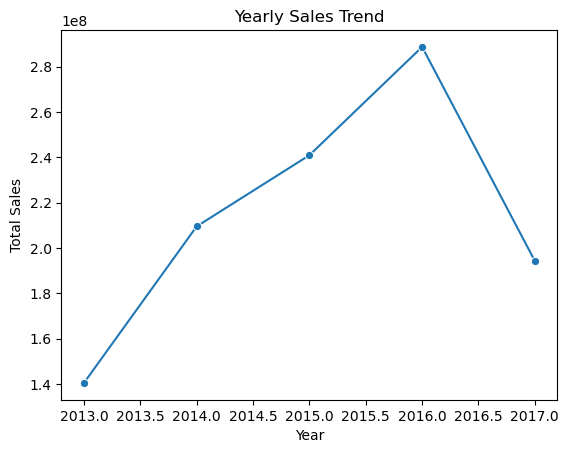

In [16]:
# Visualizing Yearly Trend 
yearly_sales = data.groupby('year')['sales'].sum().reset_index()

sns.lineplot(
    x='year',
    y='sales',
    data=yearly_sales,
    marker='o'
)

plt.title('Yearly Sales Trend')
plt.xlabel('Year')
plt.ylabel('Total Sales')
plt.show()

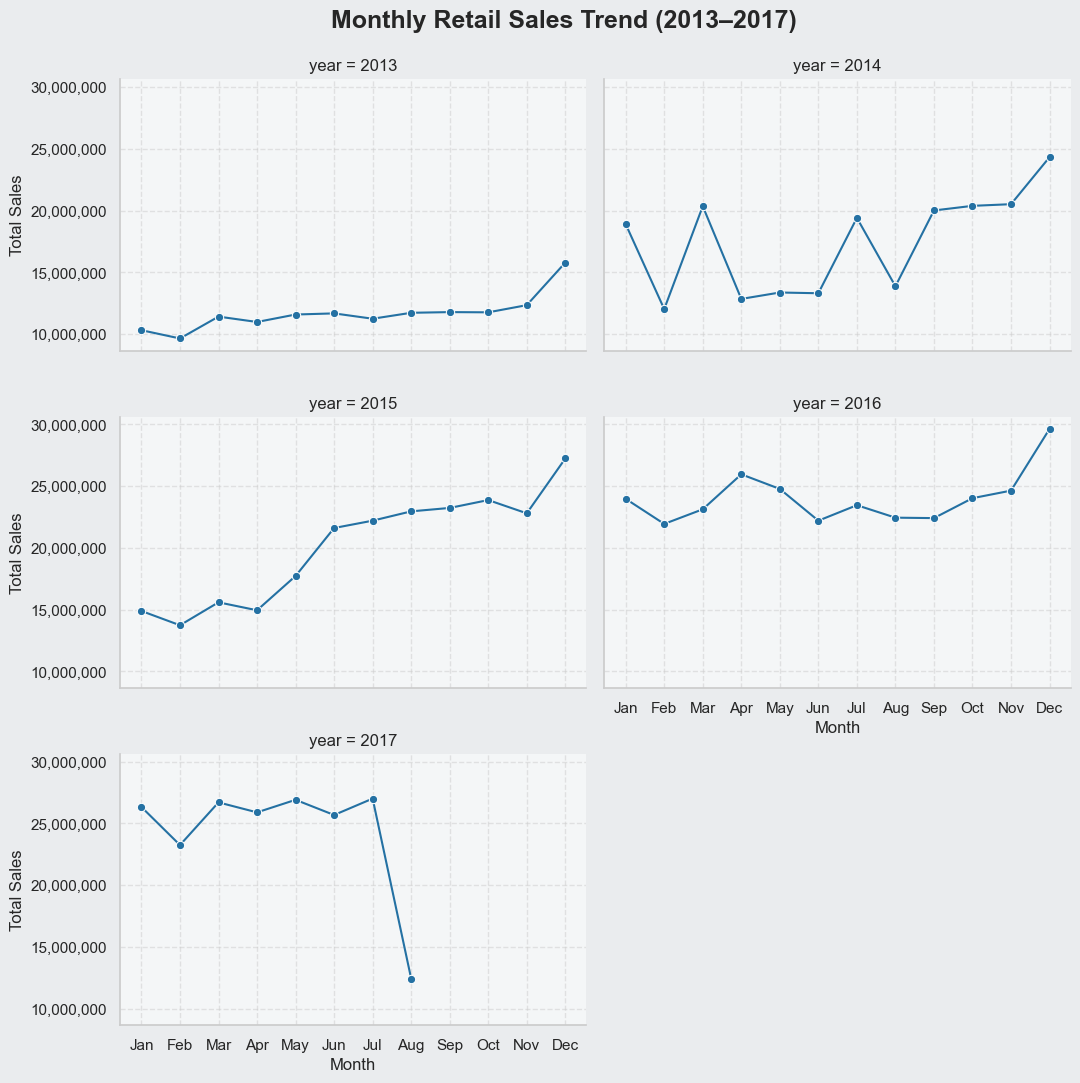

In [90]:
# Set the visual style
sns.set_theme(style="whitegrid", context="notebook")

# Month names
month_names = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
]

# Create the charts
g = sns.relplot(
    x='month',
    y='sales',
    col='year',
    col_wrap=2,
    data=yearly_sales,
    kind='line',
    marker='o',
    height=3.5,
    aspect=1.5,
    color='#2471A3'
)

# Add an overall title
g.figure.suptitle(
    'Monthly Retail Sales Trend (2013–2017)',
    fontsize=18,
    fontweight='bold',
    y=1.03
)

# Format each chart
for ax in g.axes.flat:
    ax.yaxis.set_major_formatter(
        ticker.StrMethodFormatter('{x:,.0f}')
    )

    # Display all months under the x-axis
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(month_names)

    ax.set_facecolor('#F4F6F7')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.set_xlabel('Month')
    ax.set_ylabel('Total Sales')

# Set the figure background
g.figure.set_facecolor('#EAECEE')

plt.show()

In [17]:
data.head()

,id,date,store_nbr,family,sales,onpromotion,year,month,day_of_week
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,2013,1,1
1,1,2013-01-01,1,BABY CARE,0.0,0,2013,1,1
2,2,2013-01-01,1,BEAUTY,0.0,0,2013,1,1
3,3,2013-01-01,1,BEVERAGES,0.0,0,2013,1,1
4,4,2013-01-01,1,BOOKS,0.0,0,2013,1,1


In [47]:
# number of stores 
data['store_nbr'].nunique()

54

In [56]:
# Calculate total sales for each store
store_sales = (data.groupby("store_nbr")["sales"].sum().reset_index().sort_values(by="sales", ascending=False))

# Display the top 10 stores
top_10_stores = store_sales.head(10)

top_10_stores

,store_nbr,sales
43,44,6.208755e+07
44,45,5.449801e+07
46,47,5.094831e+07
2,3,5.048191e+07
48,49,4.342010e+07
45,46,4.189606e+07
47,48,3.593313e+07
50,51,3.291149e+07
7,8,3.049429e+07
49,50,2.865302e+07


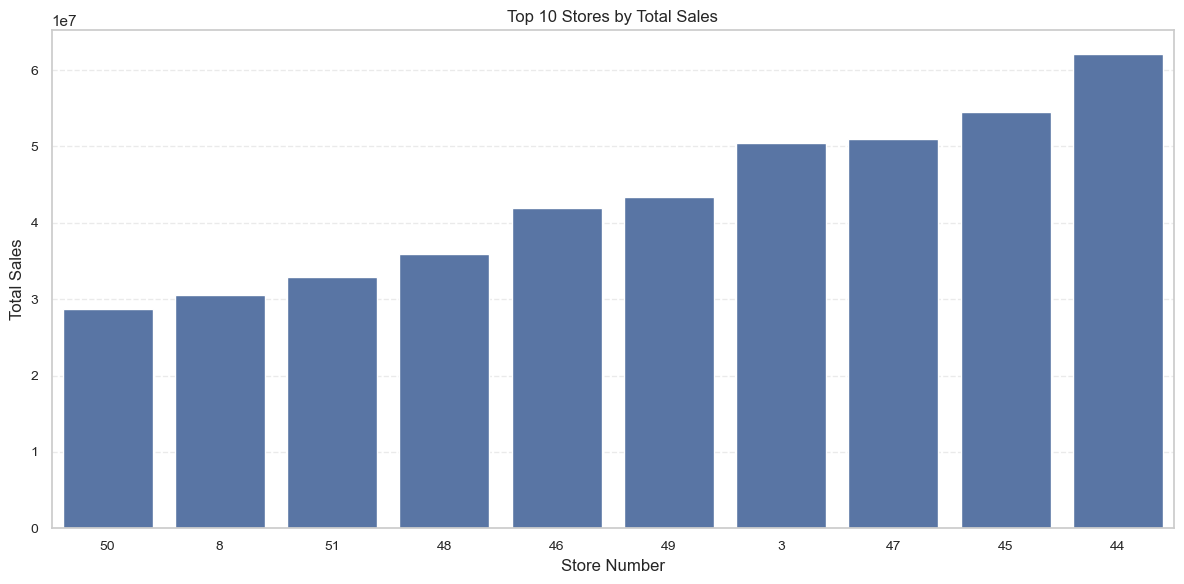

In [63]:
# Sort the top 10 stores from lowest to highest sales
top_10_stores = top_10_stores.sort_values(
    by="sales",
    ascending=True
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x="store_nbr",
    y="sales",
    data=top_10_stores,
    order=top_10_stores["store_nbr"]
)

plt.title("Top 10 Stores by Total Sales")
plt.xlabel("Store Number")
plt.ylabel("Total Sales")

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [66]:
# unique product 
data["family"].unique()

array(['AUTOMOTIVE', 'BABY CARE', 'BEAUTY', 'BEVERAGES', 'BOOKS',
       'BREAD/BAKERY', 'CELEBRATION', 'CLEANING', 'DAIRY', 'DELI', 'EGGS',
       'FROZEN FOODS', 'GROCERY I', 'GROCERY II', 'HARDWARE',
       'HOME AND KITCHEN I', 'HOME AND KITCHEN II', 'HOME APPLIANCES',
       'HOME CARE', 'LADIESWEAR', 'LAWN AND GARDEN', 'LINGERIE',
       'LIQUOR,WINE,BEER', 'MAGAZINES', 'MEATS', 'PERSONAL CARE',
       'PET SUPPLIES', 'PLAYERS AND ELECTRONICS', 'POULTRY',
       'PREPARED FOODS', 'PRODUCE', 'SCHOOL AND OFFICE SUPPLIES',
       'SEAFOOD'], dtype=object)

In [68]:
# Count of product sold 
data["family"].value_counts()

family
AUTOMOTIVE                    90936
HOME APPLIANCES               90936
SCHOOL AND OFFICE SUPPLIES    90936
PRODUCE                       90936
PREPARED FOODS                90936
POULTRY                       90936
PLAYERS AND ELECTRONICS       90936
PET SUPPLIES                  90936
PERSONAL CARE                 90936
MEATS                         90936
MAGAZINES                     90936
LIQUOR,WINE,BEER              90936
LINGERIE                      90936
LAWN AND GARDEN               90936
LADIESWEAR                    90936
HOME CARE                     90936
HOME AND KITCHEN II           90936
BABY CARE                     90936
HOME AND KITCHEN I            90936
HARDWARE                      90936
GROCERY II                    90936
GROCERY I                     90936
FROZEN FOODS                  90936
EGGS                          90936
DELI                          90936
DAIRY                         90936
CLEANING                      90936
CELEBRATION          

In [18]:
# Total sales by product family
family_sales = (data.groupby("family")["sales"].sum().sort_values(ascending=False))

family_sales

family
GROCERY I                     3.434627e+08
BEVERAGES                     2.169545e+08
PRODUCE                       1.227047e+08
CLEANING                      9.752129e+07
DAIRY                         6.448771e+07
BREAD/BAKERY                  4.213395e+07
POULTRY                       3.187600e+07
MEATS                         3.108647e+07
PERSONAL CARE                 2.459205e+07
DELI                          2.411032e+07
HOME CARE                     1.602274e+07
EGGS                          1.558830e+07
FROZEN FOODS                  1.407389e+07
PREPARED FOODS                8.799895e+06
LIQUOR,WINE,BEER              7.746640e+06
SEAFOOD                       2.015432e+06
GROCERY II                    1.962767e+06
HOME AND KITCHEN I            1.861491e+06
HOME AND KITCHEN II           1.520670e+06
CELEBRATION                   7.611770e+05
LINGERIE                      6.531140e+05
LADIESWEAR                    6.511590e+05
PLAYERS AND ELECTRONICS       5.626080e+05
AUTO

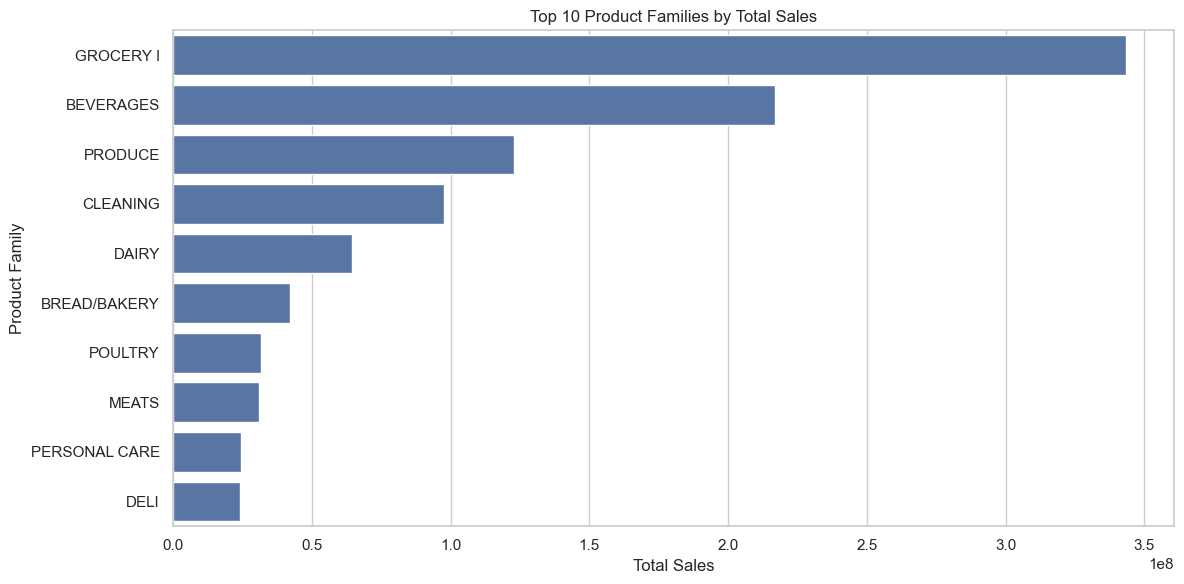

In [70]:
# Get the top 10 product families by total sales
top_10_families = family_sales.nlargest(10).reset_index()

# Plot
plt.figure(figsize=(12, 6))

sns.barplot(
    x="sales",
    y="family",
    data=top_10_families
)

plt.title("Top 10 Product Families by Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Family")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [87]:
# Calculate total sales for each product family in each year
yearly_family_sales = (
    data.groupby(["year", "family"])["sales"].sum().reset_index())


In [73]:
top_families = (
    family_sales.nlargest(10)
    .index
)

yearly_top_families = yearly_family_sales[
    yearly_family_sales["family"].isin(top_families)
]

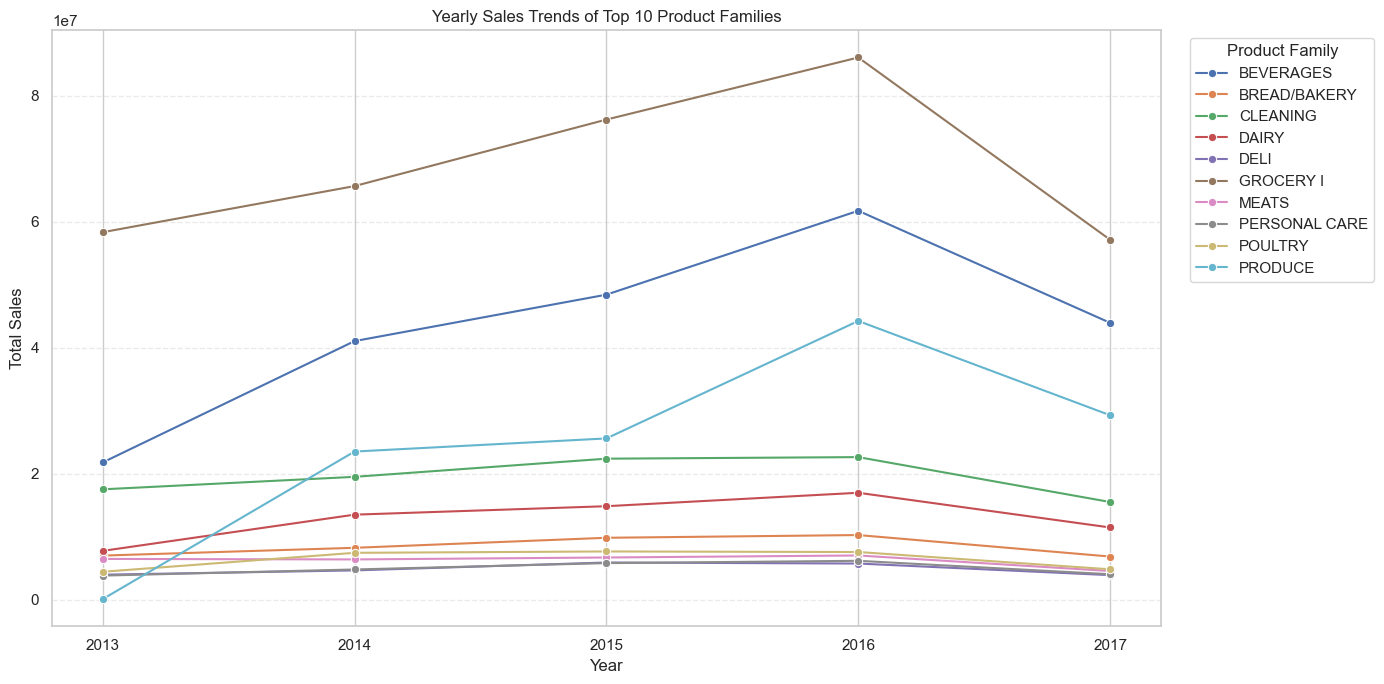

In [74]:
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=yearly_top_families,
    x="year",
    y="sales",
    hue="family",
    marker="o"
)

plt.title("Yearly Sales Trends of Top 10 Product Families")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.xticks(sorted(data["year"].unique()))
plt.legend(title="Product Family", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

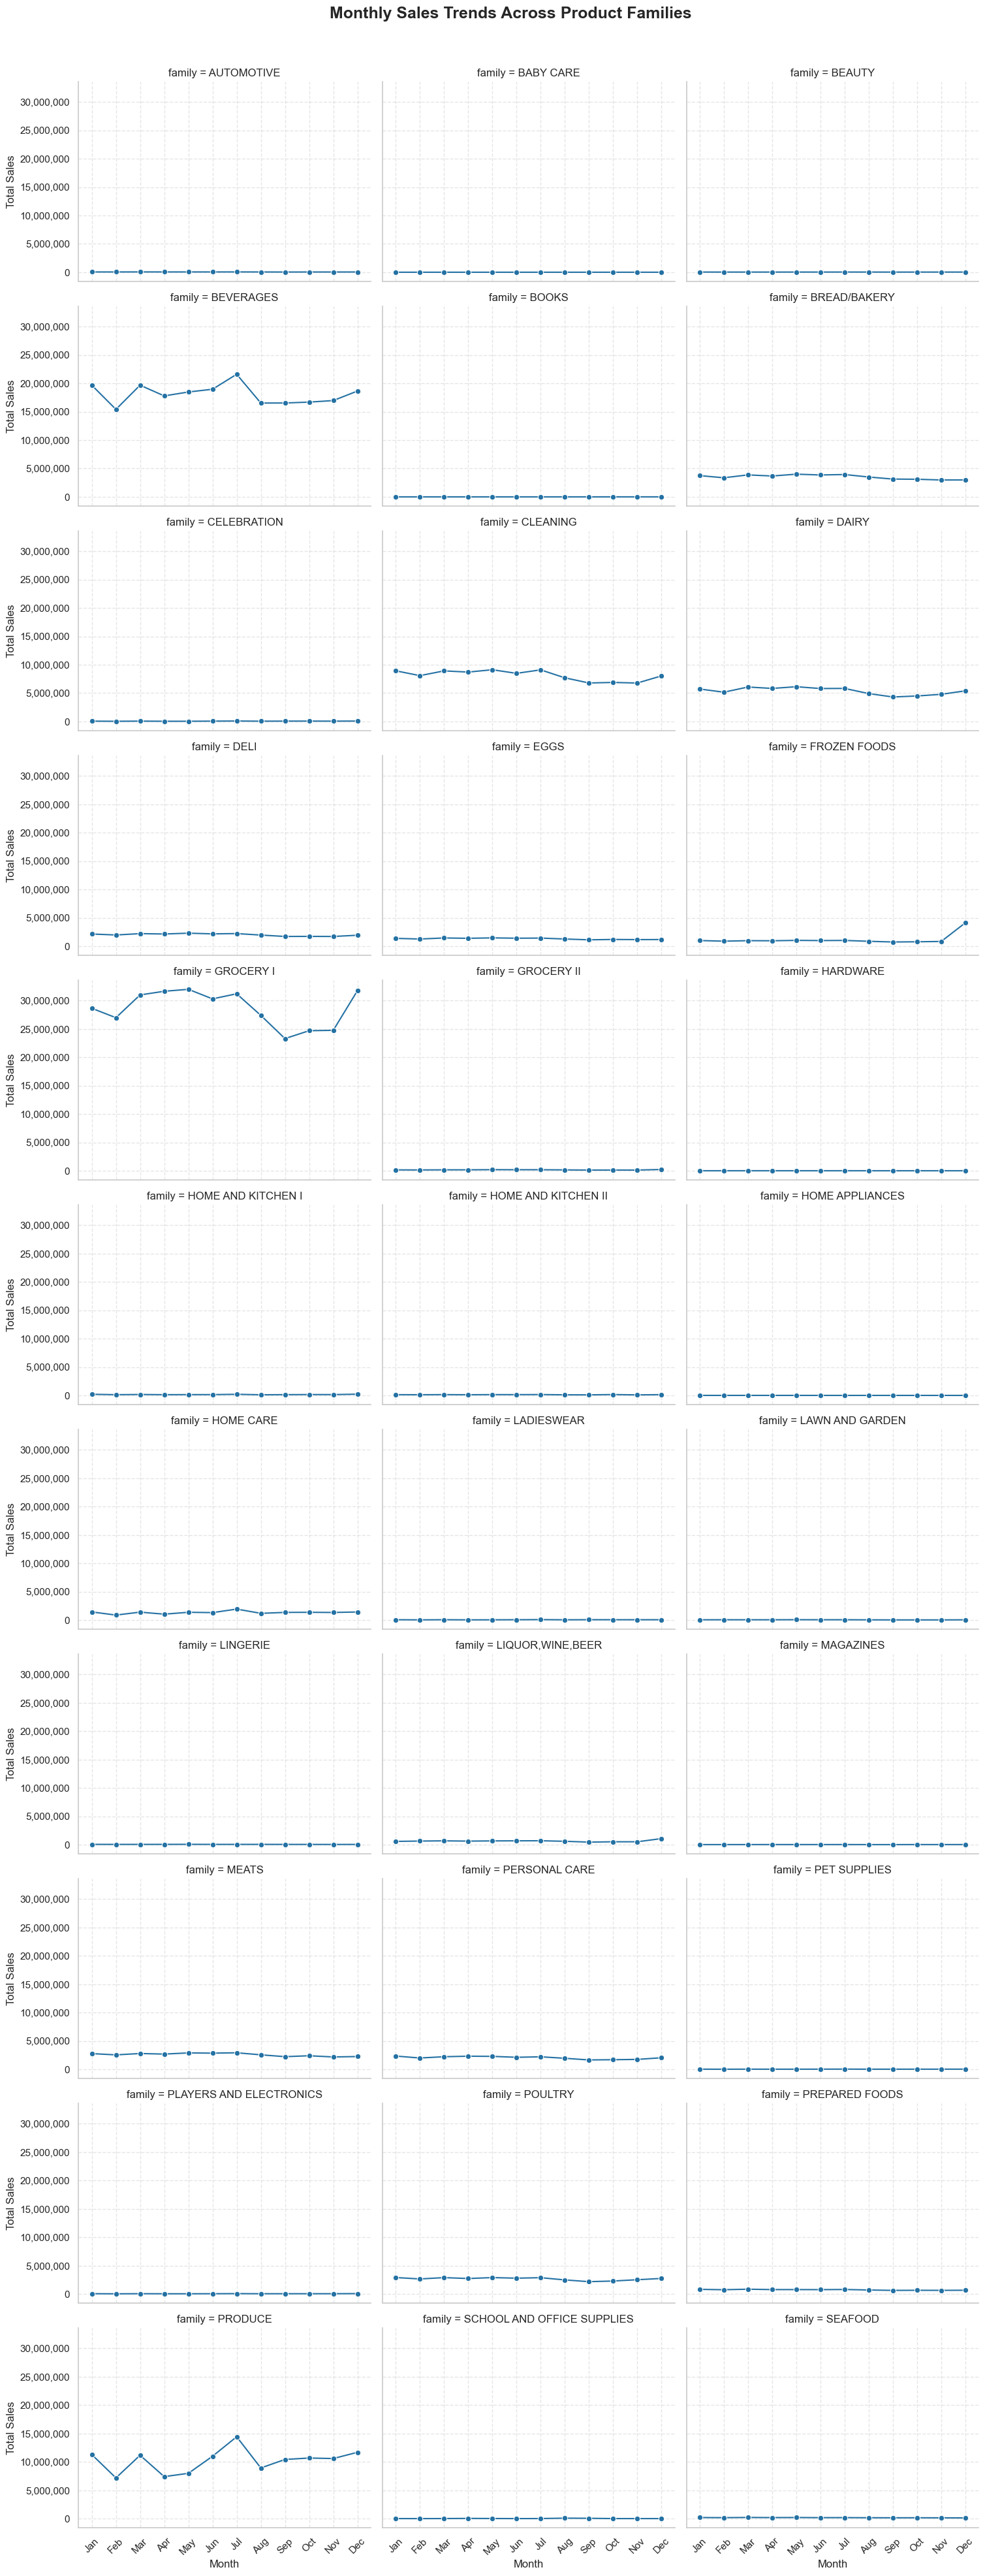

In [91]:
# Calculate total sales for each product family in each month
monthly_family_sales = (data.groupby(["family", "month"])["sales"].sum().reset_index())

sns.set_theme(style="whitegrid", context="notebook")

g = sns.relplot(
    data=monthly_family_sales,
    x="month",
    y="sales",
    col="family",
    col_wrap=3,
    kind="line",
    marker="o",
    height=3.5,
    aspect=1.4,
    color="#2471A3"
)

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

for ax in g.axes.flat:
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(month_names, rotation=45)
    ax.yaxis.set_major_formatter(
        ticker.StrMethodFormatter("{x:,.0f}")
    )
    ax.set_xlabel("Month")
    ax.set_ylabel("Total Sales")
    ax.grid(True, linestyle="--", alpha=0.5)

g.figure.suptitle(
    "Monthly Sales Trends Across Product Families",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

plt.show()

In [14]:
data.head()

,id,date,store_nbr,family,sales,onpromotion,year,month,day_of_week
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,2013,1,1
1,1,2013-01-01,1,BABY CARE,0.0,0,2013,1,1
2,2,2013-01-01,1,BEAUTY,0.0,0,2013,1,1
3,3,2013-01-01,1,BEVERAGES,0.0,0,2013,1,1
4,4,2013-01-01,1,BOOKS,0.0,0,2013,1,1


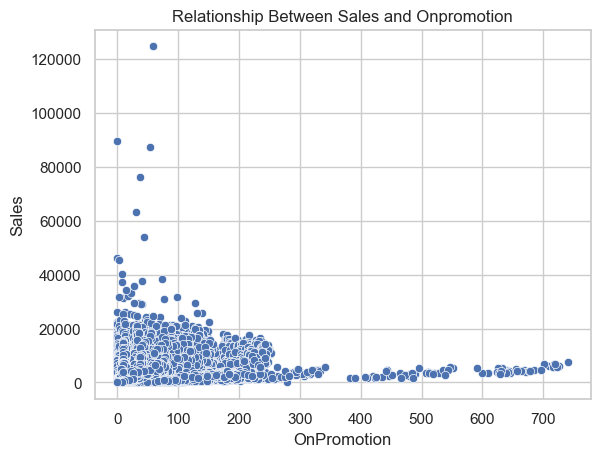

In [96]:
# Check the relationship between on promotion and sales 
sns.scatterplot(x = "onpromotion", y ="sales", 
                data = data)
plt.xlabel("OnPromotion")
plt.ylabel("Sales")
plt.title("Relationship Between Sales and Onpromotion")
plt.show()

In [12]:
# Calculate Pearson correlation
correlation = data["onpromotion"].corr(data["sales"])

print("Correlation:", correlation)

Correlation: 0.4279232048121315


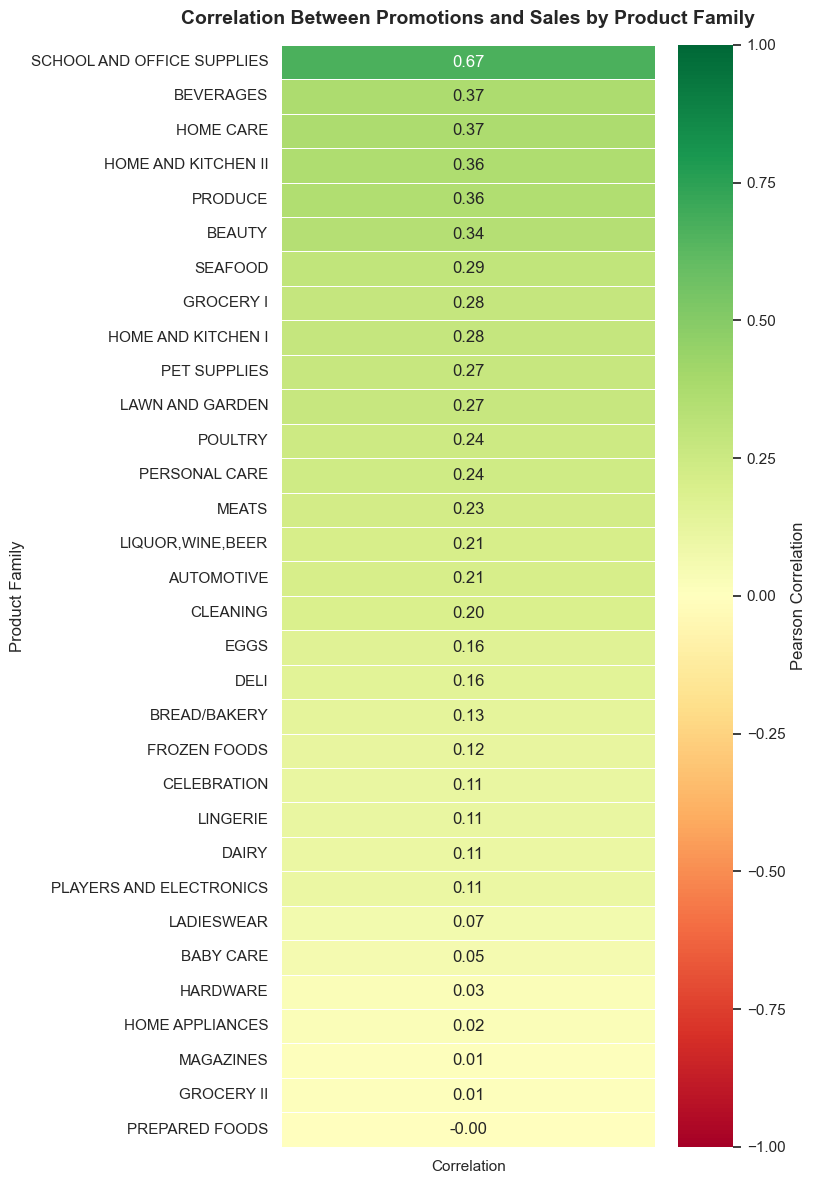

In [100]:
# Correlation between each product Onpromotion and sales 
family_correlation = (data.groupby("family").apply(lambda x: x["onpromotion"].corr(x["sales"])).sort_values(ascending=False))


# Convert correlation results into a DataFrame
heatmap_data = family_correlation.dropna().to_frame(name="Correlation")

# Sort by correlation
heatmap_data = heatmap_data.sort_values(by="Correlation",ascending=False)


# Create heatmap
plt.figure(figsize=(8, 12))

sns.heatmap(
    heatmap_data,
    annot=True,
    cmap="RdYlGn",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    cbar_kws={"label": "Pearson Correlation"}
)

plt.title(
    "Correlation Between Promotions and Sales by Product Family",
    fontsize=14,
    fontweight="bold",
    pad=15
)

plt.xlabel("")
plt.ylabel("Product Family")

plt.tight_layout()
plt.show()

In [22]:
data.head()

,id,date,store_nbr,family,sales,onpromotion,year,month,day_of_week
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,2013,1,1
1,1,2013-01-01,1,BABY CARE,0.0,0,2013,1,1
2,2,2013-01-01,1,BEAUTY,0.0,0,2013,1,1
3,3,2013-01-01,1,BEVERAGES,0.0,0,2013,1,1
4,4,2013-01-01,1,BOOKS,0.0,0,2013,1,1


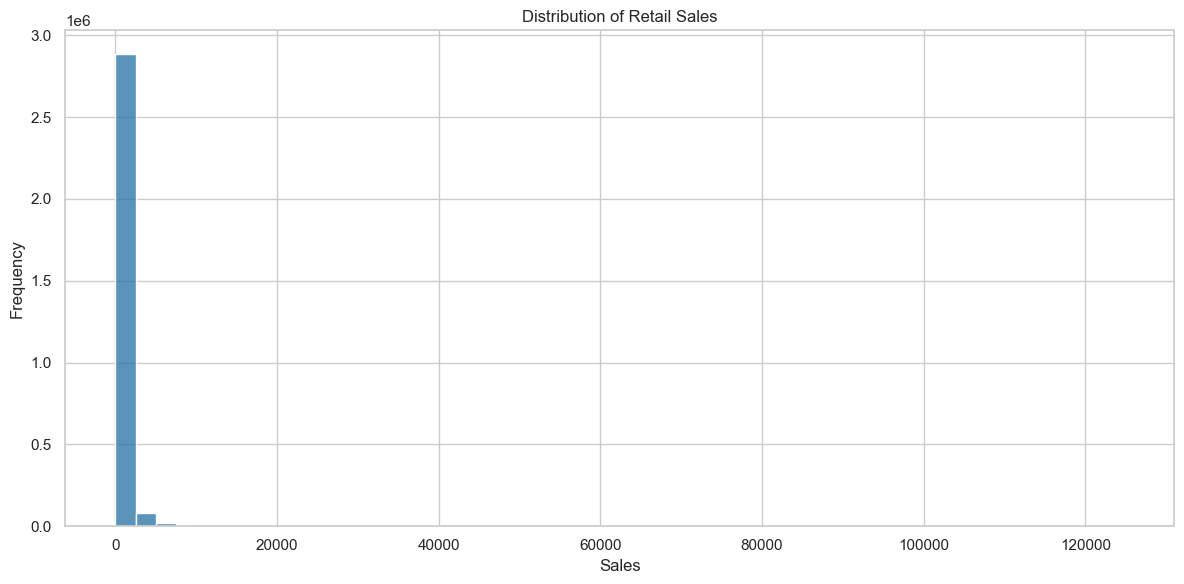

In [104]:
# Distribution of Sales 
plt.figure(figsize=(12, 6))

sns.histplot(
    data=data,
    x="sales",
    bins=50,
    color="#2471A3"
)

plt.title("Distribution of Retail Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [105]:
data["sales"].describe()

count    3.000888e+06
mean     3.577757e+02
std      1.101998e+03
min      0.000000e+00
25%      0.000000e+00
50%      1.100000e+01
75%      1.958473e+02
max      1.247170e+05
Name: sales, dtype: float64

In [23]:
data["sales"].skew()

7.358757818882655

In [15]:
# Take the log transformation
import numpy as np
data["sales_log"] = np.log1p(data["sales"])

# Model 

In [16]:
# Import Library
# Split dataset
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error,r2_score, root_mean_squared_error

In [17]:
# Apply One-Hot Encoding to convert the categorical product family
# into numerical binary columns for machine learning.
data = pd.get_dummies(data, columns=["family"], dtype=int)

In [18]:
# Drop "id" column
data.drop("id", axis = 1,inplace = True)

In [19]:
# Create the feature matrix by excluding both target columns
X = data.drop(columns=["date", "sales", "sales_log"])

In [20]:
# Create the y variable 
y = data["sales_log"]

In [21]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=43)

In [22]:
# Regression Model 
reg = LinearRegression()
reg.fit(X_train, y_train)

LinearRegression()

In [23]:
reg_pred = reg.predict(X_test)
r2 = r2_score(y_test, reg_pred)
rmse = root_mean_squared_error(y_test, reg_pred)

print(f"The RMSE Score is {rmse}\n The R^2 is {r2}")

The RMSE Score is 1.4905066623284586
 The R^2 is 0.6939518023393974


In [24]:
# Xgboost 
xgb = XGBRegressor()
xgb.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...)

In [25]:
xgb_pred = xgb.predict(X_test)

Xgb_r2 = r2_score(y_test, xgb_pred)
Xgb_rmse = root_mean_squared_error(y_test, xgb_pred)

print(f"The RMSE Score is {Xgb_rmse}\n The R^2 is {Xgb_r2}")

The RMSE Score is 0.715826614641533
 The R^2 is 0.9294108965208465


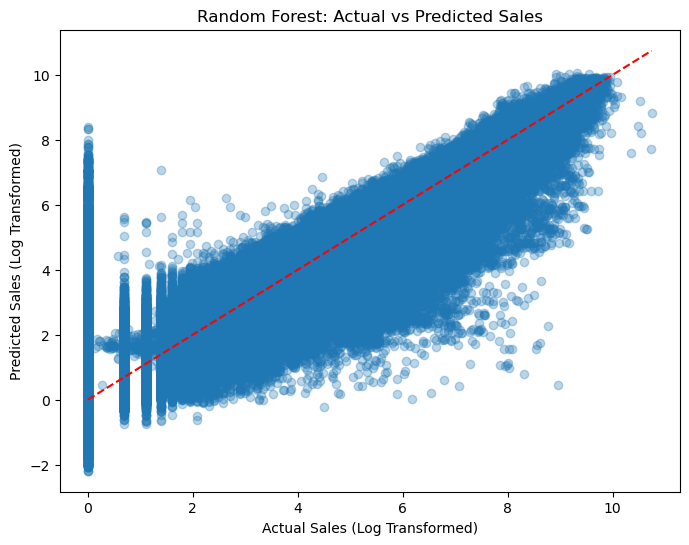

In [26]:
# Scaterplot of Xgboost Prediction
plt.figure(figsize=(8, 6))
plt.scatter(y_test, xgb_pred, alpha=0.3)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Sales (Log Transformed)")
plt.ylabel("Predicted Sales (Log Transformed)")
plt.title("Xgboost: Actual vs Predicted Sales")
plt.show()

In [42]:
import pickle

# Create the model bundle
model_artifact = {
    "model": xgb,
    "feature_names": X_train.columns.tolist(),
    "target_transform": "log1p"
}

# Save the model bundle
with open("xgboost_bundle.pkl", "wb") as file:
    pickle.dump(model_artifact, file)


In [43]:
import os

file_size = os.path.getsize("xgboost_bundle.pkl") / (1024 ** 2)

print(f"Model size: {file_size:.2f} MB")


Model size: 0.48 MB


In [32]:
evaluation_results = pd.DataFrame({
    "actual_sales": y_test.values,
    "predicted_sales": xgb_pred
})

evaluation_results.to_csv("evaluation_results.csv", index=False)